<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QLSTM_DDoS_Tripathi2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QLSTM for DDoS identification: Tripathi, Upadhyay and Soni (2025) step by step

**Paper.** S. Tripathi, H. Upadhyay, J. Soni, *Quantum Long Short-Term Memory-based Identification of Distributed Denial of Service Attacks*, 4th IEEE International Conference on AI in Cybersecurity (ICAIC), Houston, February 2025. DOI: [10.1109/ICAIC63015.2025.10849228](https://doi.org/10.1109/ICAIC63015.2025.10849228).

**What this notebook does.** It rebuilds the paper's experiment from the ground up with a plain-language explanation of every step. A network-traffic table (one row per network flow) is turned into short *time series* (10 consecutive flows, 34 features each); a classical two-layer LSTM (Keras, as in the paper) and a **quantum LSTM (QLSTM)**, in which each of the four LSTM gates is a variational quantum circuit on 6 qubits (PennyLane), are trained to say whether a DDoS attack is going on. The notebook then redraws the paper's loss/accuracy curves (Figs. 9-12) and Tables I and II, adds the classical baselines the paper does not contain (Random Forest, SVC, a classical LSTM trained exactly like the QLSTM), and checks every claim of the paper with an explicit verdict.

**How to run it.** Open in Google Colab, keep the normal CPU runtime (no GPU, no account, no quantum hardware), choose *Runtime, then Run all*. `FAST_MODE = True` (default, set in the configuration cell) is a class demo with 640 training windows and two seeds. We executed it in 29 to 40 minutes of wall-clock time (two executions) on a CPU that was shared with about eight other jobs (its CPU time is a fraction of that; we have not timed it on an idle machine). `FAST_MODE = False` uses 3,200 training windows and three seeds; that setting is written down in the configuration cell but was **not executed** for the committed notebook because it would take several hours on the shared machine. The paper's own budget, 180,000 windows x 20 epochs at batch size 16 on a state-vector simulator, would take days.

**What you get at the end.** The dataset explored and plotted (the real flows, coloured by their true label), the executed quantum circuit drawn and verified against a second simulator, the paper's figures and tables redrawn with our numbers, a side-by-side table with one verdict per claim, a critical reading (the paper's tables contradict its own text in several places) and five exercises.

**A note on the data.** The paper names "CIC-DDoS2019" on Kaggle, but the numbers it quotes (225,745 rows, 128,027 DDoS and 97,718 benign flows, 85 columns) are exactly those of the **Friday-afternoon DDoS capture of CIC-IDS2017**. We use that public file (Hugging Face mirror `c01dsnap/CIC-IDS2017`) and check the counts below.

## The paper in one page

* **Problem.** A Distributed Denial of Service (DDoS) attack floods a server with traffic from many sources. Flow-level features (packet counts, byte counts, inter-arrival times, TCP flags) look different during an attack than in normal traffic. Because attack traffic arrives in bursts, the *sequence* of recent flows carries information, so the authors use recurrent networks.
* **Decision.** Binary, per time window: DDoS (1) or benign (0).
* **Data.** Kaggle "DDoS Evaluation Dataset" (Canadian Institute for Cybersecurity): about 225,000 entries, 128,027 DDoS and 97,718 benign, more than 85 columns. The training array is `(225,735, 10, 34)`: 225,735 = 225,745 - 10 windows of 10 time steps with 34 features.
* **Pre-processing.** Drop features that do not change, drop duplicate features, and drop one feature of every pair with correlation above 0.90 (Total Forward Packets / Total Length of Backward Packets, Forward Header Length / Backward Header Length are the paper's examples).
* **Classical model.** Two LSTM layers (`lstm_1`, `lstm_2`), dropout 0.01, dense layer with a sigmoid, Adam, 100 epochs, batch size 1024, 20% validation (Keras).
* **Quantum model (QLSTM).** The same LSTM, but the transformation inside each of the forget, input, cell-update and output gates is a variational quantum circuit (VQC): Hadamard gates, data encoding, rotation gates with CNOT entanglement, Pauli-Z expectation values. 6 qubits, 20 epochs, batch size 16. Simulated (the paper mentions an "emulation environment").
* **Claims.** (i) Both models train quickly: accuracy 0.99 and above within a few epochs. (ii) Table I, classical LSTM: recall 90.06%, precision 99.82%, accuracy 90.24%, F1 94.69%. (iii) Table II, QLSTM: recall 99.65%, precision 99.43%, accuracy 99.65%, F1 99.69%. (iv) QLSTM is better than the classical LSTM on all four metrics. (v) QLSTM takes more time to train because it is simulated. (vi) QLSTM training loss about 0.03 and validation loss 0.0195 after 20 epochs, training accuracy 0.995, validation accuracy 1.0; the text also says the classical LSTM reaches accuracy .9983 and loss .0088 (which contradicts its own Table I).

## What follows the paper and what had to be chosen

The paper does not release code, gives no layer sizes (its Fig. 6 is an image), no learning rate for the QLSTM, no train/validation protocol beyond "20% validation", and no circuit diagram text. Every missing item is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | "DDoS Evaluation Dataset (CIC-DDoS2019)" from Kaggle: 225k rows, 128,027 DDoS / 97,718 benign | The identical row counts occur in the CIC-IDS2017 Friday-afternoon DDoS file; we use it from a public Hugging Face mirror and assert the counts |
| Time series | 225,735 windows of 10 steps x 34 features | Windows of 10 consecutive flows in file order (the file is time-ordered); the label is the one of the flow that **follows** the window (225,745 - 10 = 225,735 windows, so this is the only reading that gives the paper's count). A random sample of windows is used (simulation cost) |
| Features | 34 after dropping constant, duplicate and correlated (>0.90) features | Same three rules, fitted on training rows only. 35 features survive here (not 34: the rule alone does not fix the count, the paper's exact tie-breaking is unknown); the model input size follows from it |
| Split | "20% validation", not further specified | Block-wise: the file is cut into blocks of 500 consecutive flows, 20% of the blocks are held out; windows never cross a block border, so no flow is shared between train and held-out windows. No hyper-parameter is tuned on the held-out part, the numbers reported are the **last epoch** |
| Scaling | not stated | signed log1p (flow features are heavy tailed), then `StandardScaler`, clipped to [-5, 5], fitted on training rows only |
| Classical LSTM | 2 LSTM layers, dropout 0.01, dense sigmoid, Adam, 100 epochs, batch 1024; layer sizes only in Fig. 6 | Keras: LSTM(64, return sequences) -> LSTM(32) -> Dropout(0.01) -> Dense(1, sigmoid), Adam (default lr 0.001), 100 epochs, batch 32 (FAST) / 64 (full) because our training set is far smaller than 180,000 windows |
| QLSTM cell | Chen-Yoo-Fang QLSTM; four VQCs; amplitude-style encoding with Hadamards; 6 qubits; 20 epochs; batch 16 | Same cell: `v_t = [h_(t-1), x_t]` -> linear -> 6 numbers -> four VQCs -> linear -> gates. Hidden size 16 (CHOICE), Adam lr 0.01 (CHOICE), 20 epochs, batch 16 |
| Circuit | Hadamards, encoding, "rotation gates", expectation values (Fig. 8 not readable as text) | Hadamard on every qubit, RY(arctan x) and RZ(arctan x^2) encoding (the Chen et al. QLSTM encoding), then 2 layers of [CNOT ladder, Rot(phi, theta, omega) on every qubit], Pauli-Z read-out. Depth 2 is our CHOICE |
| Simulator | not stated ("emulation environment") | PennyLane `default.qubit` is the reference; a PyTorch state-vector twin of the *same* circuit is used for speed and is asserted equal to PennyLane (values and gradients, 1e-12) and checked on a full QLSTM forward/backward pass |
| Training-set size | all (about 180,000 windows) | `N_TRAIN` random training windows (640 in FAST_MODE, 3,200 in the full run), `N_TEST` held-out windows; the same windows for every model |
| Baselines | classical LSTM only | + classical LSTM trained exactly like the QLSTM (PyTorch, same hidden size, batch, epochs, optimiser), Random Forest, SVC (RBF) on the flattened window and on the last flow only |
| Seeds | not stated | `SEED = 42`; mean and standard deviation over `N_SEEDS` model seeds (data split fixed) |

## 0. Setup

Colab already ships NumPy, pandas, scikit-learn, matplotlib, TensorFlow/Keras and PyTorch. We add PennyLane, the framework used for the quantum circuits (and `huggingface_hub` for the data download). The next cell does nothing when PennyLane is already installed. If Colab asks you to restart the session after it, accept, then run the notebook again from the next cell.

In [1]:
# Colab already ships numpy, pandas, scikit-learn, matplotlib, tensorflow/keras and torch. We add PennyLane (pinned to the tested version).
# The cell does nothing when PennyLane is already available (for example on a local machine).
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("huggingface_hub") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "requests"], check=True)
    print("Installed pennylane==0.45.1. If Colab asks you to restart the session, accept and run again from the next cell.")
else:
    print("PennyLane and huggingface_hub already available, nothing to install.")

PennyLane and huggingface_hub already available, nothing to install.


The **configuration cell** holds every tunable constant. `FAST_MODE` shrinks the training sets and the number of seeds so that the whole notebook runs in about 10 minutes; `FAST_MODE = False` is the larger run. No quantum-hardware token is needed because the paper used a simulator (`IBM_TOKEN` is kept for the convention and is not used).

In [2]:
# ------------------------------- configuration: every tunable constant lives here -------------------------------
SEED = 42
FAST_MODE = True       # True: about 10 minute class demo. False: larger training sets, 3 seeds (budgets below).
DATA_DIR = "ddos2017_data"      # cache folder for the downloaded CSV
LOCAL_CSV = ""                  # optional: path of an uploaded copy of Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
IBM_TOKEN = ""                  # not used: the paper ran a simulator only (kept for the convention)

HF_REPO = "c01dsnap/CIC-IDS2017"
HF_FILE = "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"

# --- constants from the paper ---
T_STEPS     = 10      # time steps per window (paper: 10)
N_QUBITS    = 6       # paper: 6 qubits for 34 features
CORR_THR    = 0.90    # paper: correlation threshold 0.90
DROPOUT     = 0.01    # paper: dropout 0.01
KERAS_EPOCHS = 100    # paper: classical LSTM, 100 epochs (batch 1024 on ~180,000 windows, see KERAS_BATCH below)
Q_EPOCHS, Q_BATCH = 20, 16                # paper: QLSTM, 20 epochs, batch 16

# --- choices the paper leaves open (marked # CHOICE: where they are used) ---
Q_HIDDEN = 16         # CHOICE: hidden size of the QLSTM and of the matched classical LSTM (paper Fig. 6 is an image)
Q_DEPTH  = 2          # CHOICE: number of [CNOT ladder + Rot] layers in every gate circuit
Q_LR     = 0.01       # CHOICE: Adam learning rate of the QLSTM / matched LSTM (paper: typical range .001-.01)
BLOCK    = 500        # CHOICE: block length (consecutive flows) of the block-wise train/held-out split
TEST_FRAC = 0.20      # paper: 20% validation

if FAST_MODE:
    N_TRAIN, N_TEST, N_SEEDS = 640, 1000, 2
    KERAS_BATCH = 32      # CHOICE: the paper's batch 1024 suits ~180,000 windows; with ~300x fewer windows we scale the batch to keep a comparable number of updates
    RF_TREES = 100
else:
    # paper: ~180,000 training windows x 20 epochs x batch 16 = 225,000 state-vector steps per model (days on a CPU)
    N_TRAIN, N_TEST, N_SEEDS = 3200, 2000, 3
    KERAS_BATCH = 64      # CHOICE: scaled batch, see above (paper: 1024 on ~180,000 windows)
    RF_TREES = 300
SVC_MAX = 6000        # CHOICE: the RBF SVC is trained on at most this many windows (kernel SVC cost grows quadratically)

In [3]:
import os, io, time, math, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow import keras

# Hugging Face token: only needed for gated datasets (CIC-IDS2017 on this mirror is public). Never printed, never written to a file.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def set_seed(s):
    s = int(s); np.random.seed(s % (2**32 - 1)); torch.manual_seed(s); tf.random.set_seed(s); keras.utils.set_random_seed(s)

set_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| tensorflow", tf.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TRAIN =", N_TRAIN, "| N_TEST =", N_TEST, "| seeds =", N_SEEDS)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | tensorflow 2.21.0
FAST_MODE = True | N_TRAIN = 640 | N_TEST = 1000 | seeds = 2


## 1. Data: the CIC-IDS2017 Friday-afternoon DDoS capture

The Canadian Institute for Cybersecurity recorded days of network traffic and turned the packets into **flows**: all packets of one connection become one table row with 78 numeric statistics (duration, packet counts, byte counts, inter-arrival times, TCP flag counts, ...) and a label. On Friday afternoon the capture contains normal traffic ("BENIGN") and a DDoS attack ("DDoS", an HTTP flood with the LOIC tool). The rows are stored in time order, which is what lets us build time series from them.

The code downloads the file once into `DATA_DIR` (77 MB), reading it in chunks, and then **asserts that it has the row counts the paper quotes**: 225,745 rows, 128,027 DDoS and 97,718 benign.

In [4]:
def fetch_csv():
    if LOCAL_CSV and os.path.exists(LOCAL_CSV): return LOCAL_CSV
    dest = os.path.join(DATA_DIR, HF_FILE)
    if os.path.exists(dest) and os.path.getsize(dest) > 50_000_000: return dest
    try:
        from huggingface_hub import hf_hub_download
        return hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
    except Exception as e:
        print("huggingface_hub download failed:", repr(e)[:150], "-> trying the direct URL")
    url = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{HF_FILE}"
    headers = {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}
    with requests.get(url, headers=headers, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(1 << 20): f.write(chunk)
    return dest

csv_path = fetch_csv()
df = pd.concat(pd.read_csv(csv_path, encoding="latin1", chunksize=200_000), ignore_index=True)   # chunked read
df.columns = df.columns.str.strip()
LABEL_COL = "Label"
print("shape:", df.shape)
print(df[LABEL_COL].value_counts().to_string())
assert df.shape[0] == 225_745, "unexpected number of rows"
assert (df[LABEL_COL] == "DDoS").sum() == 128_027 and (df[LABEL_COL] == "BENIGN").sum() == 97_718, "class counts differ from the paper"
print("-> identical to the paper's counts: 225,745 flows, 128,027 DDoS, 97,718 benign.")
y_all = (df[LABEL_COL] != "BENIGN").astype(np.int8).to_numpy()       # attack = positive class
FEATURES_RAW = [c for c in df.columns if c != LABEL_COL]
X_raw = df[FEATURES_RAW].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
X_raw[~np.isfinite(X_raw)] = np.nan                                   # +-inf (division by zero in rate features) -> missing
print("raw numeric features:", len(FEATURES_RAW), "| missing values:", int(np.isnan(X_raw).sum()), "in", int(np.isnan(X_raw).any(1).sum()), "rows")
del df

shape: (225745, 79)
Label
DDoS      128027
BENIGN     97718
-> identical to the paper's counts: 225,745 flows, 128,027 DDoS, 97,718 benign.


raw numeric features: 78 | missing values: 68 in 34 rows


## 2. Block-wise split, pre-processing, and the time series

Three things happen here, in this order, so that **nothing from the held-out part influences training**:

1. The 225,745 time-ordered flows are cut into blocks of 500 consecutive flows and 20% of the blocks are held out. (A random split of overlapping windows would put almost identical windows in both parts; a plain "last 20%" split would be nearly all benign traffic because the file ends with normal traffic.)
2. The paper's three pre-processing rules are applied with statistics **from the training rows only**: missing values -> training median; remove constant features; remove one of every pair of features whose absolute correlation exceeds 0.90 (identical features have correlation 1, so duplicates disappear under the same rule). Then a signed `log1p` (flow features are extremely heavy tailed), `StandardScaler` and a clip to [-5, 5].
3. Windows of 10 consecutive flows (inside one block) become the model input `(10, F)`; the label of a window is the label of the flow right after it (the only reading that gives the paper's 225,735 = 225,745 - 10 windows).

In [5]:
n_rows = len(y_all); n_blocks = int(math.ceil(n_rows / BLOCK))
# CHOICE: block-wise split (see the table at the top).
test_blocks = rng.choice(n_blocks, size=int(round(TEST_FRAC * n_blocks)), replace=False)
is_test_block = np.zeros(n_blocks, bool); is_test_block[test_blocks] = True
row_block = np.arange(n_rows) // BLOCK
train_rows = ~is_test_block[row_block]; test_rows = is_test_block[row_block]
print(f"blocks: {n_blocks} of {BLOCK} flows | train rows {train_rows.sum():,} | held-out rows {test_rows.sum():,}")
print("attack share  train rows: %.3f | held-out rows: %.3f" % (y_all[train_rows].mean(), y_all[test_rows].mean()))

# ---- pre-processing fitted on TRAINING rows only ----
Xtr_rows = X_raw[train_rows]
medians = np.nanmedian(Xtr_rows, axis=0)
X_imp = np.where(np.isnan(X_raw), medians, X_raw)                             # missing -> training median
std_tr = X_imp[train_rows].std(0)
keep = std_tr > 0
print("constant features removed:", [f for f, k in zip(FEATURES_RAW, keep) if not k])
C = np.abs(np.corrcoef(X_imp[train_rows][:, keep], rowvar=False))
names_k = [f for f, k in zip(FEATURES_RAW, keep) if k]
drop = set()
for j in range(C.shape[0]):                       # CHOICE: of a correlated pair the LATER feature is dropped
    if j in drop: continue
    for k2 in range(j + 1, C.shape[0]):
        if k2 not in drop and C[j, k2] > CORR_THR: drop.add(k2)
FEATURES = [f for i, f in enumerate(names_k) if i not in drop]
print(f"correlation rule (> {CORR_THR}) removed {len(drop)} features; {len(FEATURES)} features remain (paper: 34)")
for a, b in (("Total Fwd Packets", "Total Length of Bwd Packets"), ("Fwd Header Length", "Bwd Header Length")):
    ia, ib = names_k.index(a), names_k.index(b); print(f"  corr({a}, {b}) = {C[ia, ib]:.2f}")
F_IN = len(FEATURES)
cols = [FEATURES_RAW.index(f) for f in FEATURES]

def slog(x): return np.sign(x) * np.log1p(np.abs(x))
Z = slog(X_imp[:, cols])
scaler = StandardScaler().fit(Z[train_rows])
Z = np.clip(scaler.transform(Z), -5, 5).astype(np.float32)               # all rows, scaled with training statistics

# ---- windows of T_STEPS consecutive flows inside one block; label = flow right after the window ----
all_starts = np.arange(n_rows - T_STEPS)
ok = (row_block[all_starts] == row_block[all_starts + T_STEPS])             # window and its label flow lie in the same block
starts_train = all_starts[ok & ~is_test_block[row_block[all_starts]]]
starts_test = all_starts[ok & is_test_block[row_block[all_starts]]]
print(f"admissible windows: train {len(starts_train):,} | held-out {len(starts_test):,}")
st_tr = np.sort(rng.choice(starts_train, size=min(N_TRAIN, len(starts_train)), replace=False))
st_te = np.sort(rng.choice(starts_test, size=min(N_TEST, len(starts_test)), replace=False))
def make_windows(starts):
    idx = starts[:, None] + np.arange(T_STEPS)[None, :]
    return Z[idx], y_all[starts + T_STEPS], idx
Xtr, ytr, idx_tr = make_windows(st_tr); Xte, yte, idx_te = make_windows(st_te)
print("X_train", Xtr.shape, "X_test", Xte.shape, "| attack share train %.3f test %.3f" % (ytr.mean(), yte.mean()))
assert len(np.intersect1d(idx_tr.ravel(), idx_te.ravel())) == 0, "a flow is shared between train and held-out windows"

blocks: 452 of 500 flows | train rows 180,745 | held-out rows 45,000
attack share  train rows: 0.585 | held-out rows: 0.497


constant features removed: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


correlation rule (> 0.9) removed 33 features; 35 features remain (paper: 34)
  corr(Total Fwd Packets, Total Length of Bwd Packets) = 0.94
  corr(Fwd Header Length, Bwd Header Length) = 0.95


admissible windows: train 177,125 | held-out 44,100
X_train (640, 10, 35) X_test (1000, 10, 35) | attack share train 0.588 test 0.513


## Dataset Exploration and Visualisation

We look at the data the models actually see: the original labels and class counts, the class distribution, how attack and benign flows are laid out in time, and 2-D projections of **real observations coloured by their ground-truth label** (single flows and 10-flow windows). This capture contains one attack family only, so the label has two original values, `BENIGN` and `DDoS`. Every PCA is fitted on the training split.

dataset shape (rows, columns incl. label):

 (225745, 79)
original label values and counts:


DDoS      128027
BENIGN     97718

all 78 numeric features (before pre-processing):
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PS

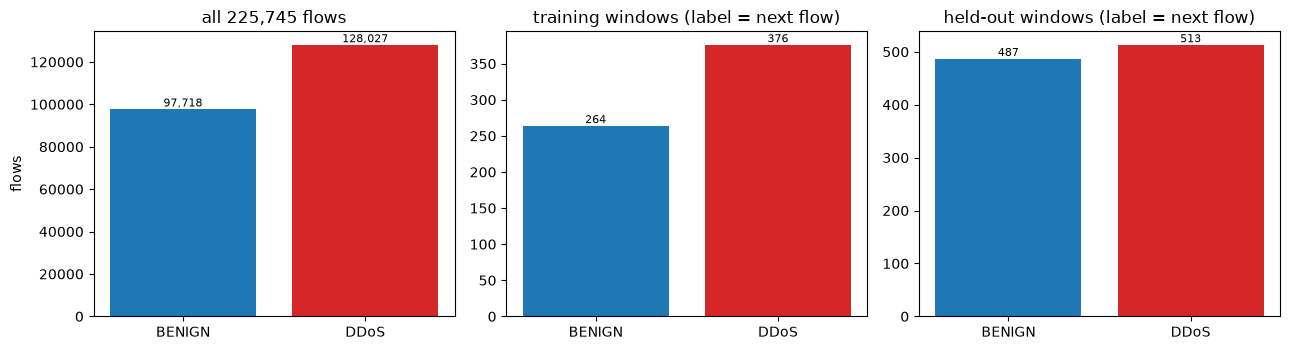

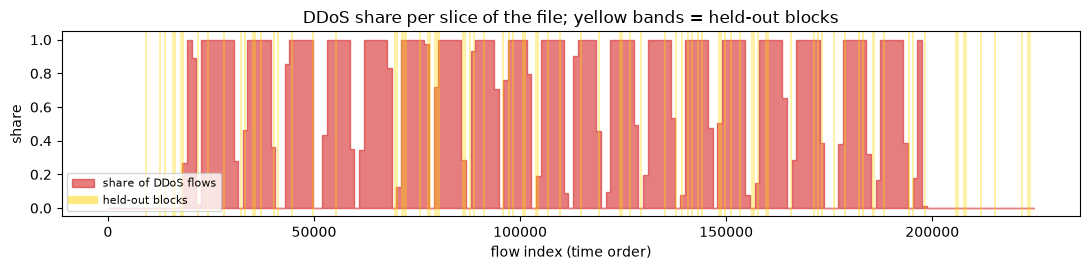

In [6]:
print("dataset shape (rows, columns incl. label):", (n_rows, len(FEATURES_RAW) + 1))
print("original label values and counts:"); print(pd.Series(np.where(y_all == 1, "DDoS", "BENIGN")).value_counts().to_string())
print("\nall %d numeric features (before pre-processing):" % len(FEATURES_RAW)); print(FEATURES_RAW)
print("\n%d features kept after pre-processing (model input):" % F_IN); print(FEATURES)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
cnt = [(y_all == 0).sum(), (y_all == 1).sum()]
b = ax[0].bar(["BENIGN", "DDoS"], cnt, color=["tab:blue", "tab:red"]); ax[0].set_title("all 225,745 flows"); ax[0].set_ylabel("flows")
for r, c_ in zip(b, cnt): ax[0].text(r.get_x() + r.get_width() / 2, c_, f"{c_:,}", ha="center", va="bottom", fontsize=8)
for k, (nm, y_, c_) in enumerate((("training windows", ytr, None), ("held-out windows", yte, None))):
    cc = [(y_ == 0).sum(), (y_ == 1).sum()]
    bb = ax[k + 1].bar(["BENIGN", "DDoS"], cc, color=["tab:blue", "tab:red"]); ax[k + 1].set_title(f"{nm} (label = next flow)")
    for r, c_ in zip(bb, cc): ax[k + 1].text(r.get_x() + r.get_width() / 2, c_, f"{c_:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

# attack share along the file (the flows are in time order) and the block split
nb_bins = 200; edges = np.linspace(0, n_rows, nb_bins + 1).astype(int)
share = [y_all[a:b_].mean() for a, b_ in zip(edges[:-1], edges[1:])]
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.fill_between(edges[:-1], share, step="post", color="tab:red", alpha=.6, label="share of DDoS flows")
for bi in test_blocks: ax.axvspan(bi * BLOCK, (bi + 1) * BLOCK, color="gold", alpha=.35, lw=0)
ax.plot([], [], color="gold", lw=6, alpha=.5, label="held-out blocks"); ax.set_xlabel("flow index (time order)"); ax.set_ylabel("share")
ax.set_title("DDoS share per slice of the file; yellow bands = held-out blocks"); ax.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

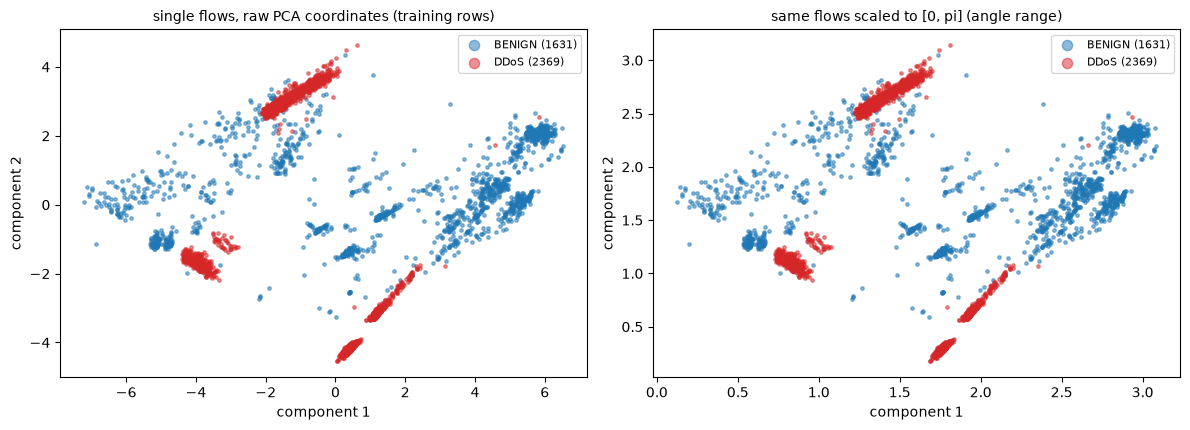

PCA explained variance of the two components (training rows): 0.304, 0.206


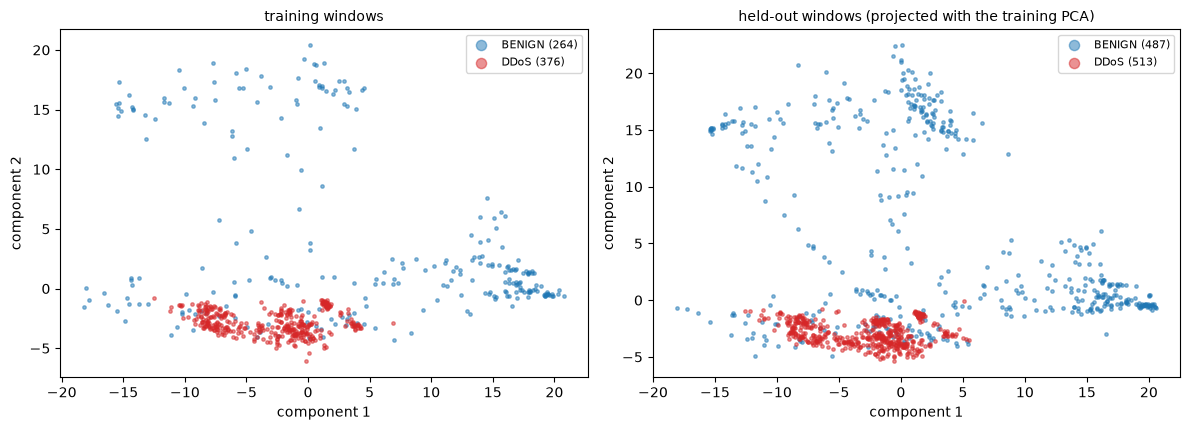

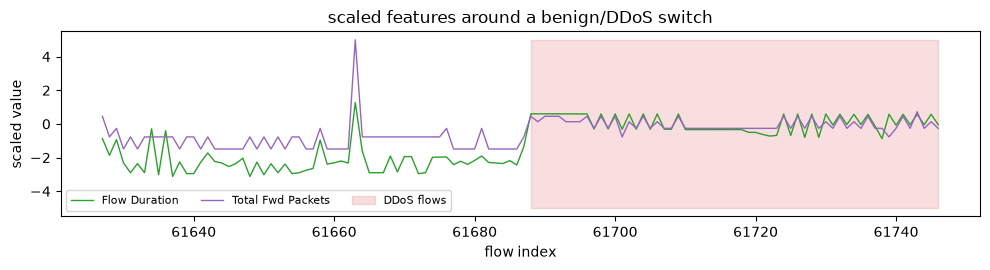

In [7]:
# ---- 2-D projection of single real flows: raw PCA coordinates (fitted on training rows), coloured by the true label ----
sub_tr = rng.choice(np.flatnonzero(train_rows), size=4000, replace=False); sub_te = rng.choice(np.flatnonzero(test_rows), size=1500, replace=False)
pca_row = PCA(n_components=2, random_state=SEED).fit(Z[train_rows])
P_tr, P_te = pca_row.transform(Z[sub_tr]), pca_row.transform(Z[sub_te])
mm = MinMaxScaler((0, np.pi)).fit(pca_row.transform(Z[train_rows]))             # same coordinates scaled to [0, pi]
A_tr, A_te = np.clip(mm.transform(P_tr), 0, np.pi), np.clip(mm.transform(P_te), 0, np.pi)
col = {0: "tab:blue", 1: "tab:red"}; lab = {0: "BENIGN", 1: "DDoS"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for k, (Pt, yt, ttl) in enumerate(((P_tr, y_all[sub_tr], "single flows, raw PCA coordinates (training rows)"), (A_tr, y_all[sub_tr], "same flows scaled to [0, pi] (angle range)"))):
    for c_ in (0, 1):
        m_ = yt == c_; ax[k].scatter(Pt[m_, 0], Pt[m_, 1], s=6, alpha=.5, c=col[c_], label=f"{lab[c_]} ({m_.sum()})")
    ax[k].set_title(ttl, fontsize=10); ax[k].set_xlabel("component 1"); ax[k].set_ylabel("component 2"); ax[k].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()
print("PCA explained variance of the two components (training rows): %.3f, %.3f" % tuple(pca_row.explained_variance_ratio_))

# ---- 2-D projection of the model inputs: whole 10-flow windows (flattened), coloured by the label of the following flow ----
pca_win = PCA(n_components=2, random_state=SEED).fit(Xtr.reshape(len(Xtr), -1))
W_tr, W_te = pca_win.transform(Xtr.reshape(len(Xtr), -1)), pca_win.transform(Xte.reshape(len(Xte), -1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for k, (Pt, yt, ttl) in enumerate(((W_tr, ytr, "training windows"), (W_te, yte, "held-out windows (projected with the training PCA)"))):
    for c_ in (0, 1):
        m_ = yt == c_; ax[k].scatter(Pt[m_, 0], Pt[m_, 1], s=6, alpha=.5, c=col[c_], label=f"{lab[c_]} ({m_.sum()})")
    ax[k].set_title(ttl, fontsize=10); ax[k].set_xlabel("component 1"); ax[k].set_ylabel("component 2"); ax[k].legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

# ---- two real features along time inside one attack burst, to show what the LSTM sees ----
j0 = int(np.flatnonzero(np.diff(y_all) != 0)[10]); seg = slice(max(0, j0 - 60), j0 + 60)
fig, ax = plt.subplots(figsize=(10, 2.8))
for fname, c_ in (("Flow Duration", "tab:green"), ("Total Fwd Packets", "tab:purple")):
    if fname in FEATURES: ax.plot(np.arange(n_rows)[seg], Z[seg, FEATURES.index(fname)], label=fname, color=c_, lw=1)
yy = y_all[seg]; ax.fill_between(np.arange(n_rows)[seg], -5, 5, where=yy == 1, color="tab:red", alpha=.15, step="mid", label="DDoS flows")
ax.set_xlabel("flow index"); ax.set_ylabel("scaled value"); ax.set_title("scaled features around a benign/DDoS switch"); ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Inside the QLSTM, **each of the four gates** (forget, input, cell update, output) is the same kind of variational quantum circuit (VQC) on 6 qubits with its own trainable angles. A window of 10 flows goes through the cell 10 times, so one prediction executes 4 x 10 circuits. The drawing below is made from the real PennyLane QNode (`default.qubit`) that the notebook uses as the reference simulator. Its pieces, in the order they act:

1. **Hadamard on every qubit**: puts the register into the equal superposition (the paper: "Hadamard gates applied N times ... unbiased initial state").
2. **Data encoding**: qubit *i* receives the classical number *x_i* (one of the 6 outputs of the cell's input linear layer) as `RY(arctan x_i)` and `RZ(arctan x_i^2)`. The arctan keeps the angles bounded in (-pi/2, pi/2).
3. **Variational layers** (`Q_DEPTH = 2`): a ladder of CNOT gates entangles neighbouring qubits, then a general rotation `Rot(phi, theta, omega)` with three *trainable* angles acts on every qubit.
4. **Measurement**: the expectation value of Pauli-Z on each qubit gives 6 real numbers that go back into the classical network.

The paper omits the circuit details (its Fig. 8 is an image), so gate set, depth and encoding are our documented assumptions (table at the top).

Matplotlib is building the font cache; this may take a moment.


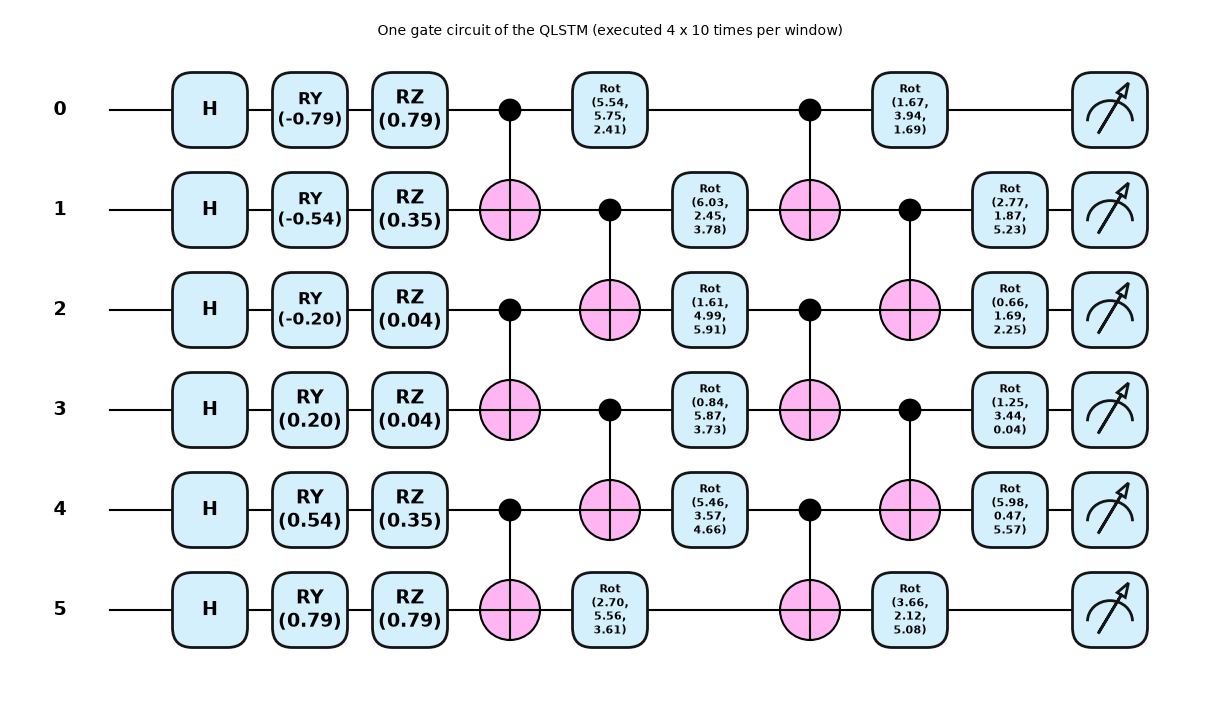

0: ──H──RY(-0.79)──RZ(0.79)─╭●──Rot(5.54,5.75,2.41)──────────────────────╭●──Rot(1.67,3.94,1.69) ···
1: ──H──RY(-0.54)──RZ(0.35)─╰X─╭●────────────────────Rot(6.03,2.45,3.78)─╰X─╭●────────────────── ···
2: ──H──RY(-0.20)──RZ(0.04)─╭●─╰X────────────────────Rot(1.61,4.99,5.91)─╭●─╰X────────────────── ···
3: ──H──RY(0.20)───RZ(0.04)─╰X─╭●────────────────────Rot(0.84,5.87,3.73)─╰X─╭●────────────────── ···
4: ──H──RY(0.54)───RZ(0.35)─╭●─╰X────────────────────Rot(5.46,3.57,4.66)─╭●─╰X────────────────── ···
5: ──H──RY(0.79)───RZ(0.79)─╰X──Rot(2.70,5.56,3.61)──────────────────────╰X──Rot(3.66,2.12,5.08) ···

0: ··· ──────────────────────┤  <Z>
1: ··· ──Rot(2.77,1.87,5.23)─┤  <Z>
2: ··· ──Rot(0.66,1.69,2.25)─┤  <Z>
3: ··· ──Rot(1.25,3.44,0.04)─┤  <Z>
4: ··· ──Rot(5.98,0.47,5.57)─┤  <Z>
5: ··· ──────────────────────┤  <Z>
qubits: 6 | circuit depth: 9 | gates: 40 | gate types: {'Hadamard': 6, 'RY': 6, 'RZ': 6, 'CNOT': 10, 'Rot': 12}
trainable parameters per gate circuit: 2 layers x 6 qubits x 3 an

In [8]:
def make_pl_vqc(n=N_QUBITS, L=Q_DEPTH):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def vqc(inputs, weights):
        for i in range(n): qml.Hadamard(wires=i)                                            # unbiased superposition
        for i in range(n): qml.RY(torch.arctan(inputs[..., i]), wires=i)                    # CHOICE: Chen et al. QLSTM encoding
        for i in range(n): qml.RZ(torch.arctan(inputs[..., i] ** 2), wires=i)
        for l in range(L):                                                                  # CHOICE: depth L, CNOT ladder + Rot layer
            for i in range(0, n - 1, 2): qml.CNOT(wires=[i, i + 1])
            for i in range(1, n - 1, 2): qml.CNOT(wires=[i, i + 1])
            for i in range(n): qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)
        return [qml.expval(qml.PauliZ(i)) for i in range(n)]                                # <Z_i>, one number per qubit
    return vqc

PL_VQC = make_pl_vqc()
x_demo = torch.linspace(-1.0, 1.0, N_QUBITS); w_demo = torch.rand(Q_DEPTH, N_QUBITS, 3) * 2 * math.pi
fig, ax = qml.draw_mpl(PL_VQC, decimals=2, style="pennylane")(x_demo, w_demo)
fig.suptitle("One gate circuit of the QLSTM (executed 4 x 10 times per window)", fontsize=10); plt.show()
print(qml.draw(PL_VQC, decimals=2)(x_demo, w_demo))

sp = qml.specs(PL_VQC)(x_demo, w_demo)
try:
    res = sp["resources"]; depth, n_gates, gate_types = res.depth, res.num_gates, dict(res.gate_types)
except Exception:
    depth, n_gates, gate_types = sp.get("depth"), sp.get("num_operations"), sp.get("gate_types")
print(f"qubits: {N_QUBITS} | circuit depth: {depth} | gates: {n_gates} | gate types: {gate_types}")
print(f"trainable parameters per gate circuit: {Q_DEPTH} layers x {N_QUBITS} qubits x 3 angles = {Q_DEPTH * N_QUBITS * 3}")
print(f"trainable circuit parameters in the whole QLSTM cell (4 gate circuits): {4 * Q_DEPTH * N_QUBITS * 3}")

### A fast twin of the circuit, proved equal to PennyLane

Training needs about 10 x 4 circuit evaluations per window and per step, with gradients. PennyLane's `default.qubit` is correct but slow in this setting, so the training loop uses a **PyTorch twin**: the same circuit written as a state-vector computation (the encoding is a product state; every layer is one 64 x 64 unitary built from the `Rot` angles; Pauli-Z expectations are read from the probabilities). The next cell proves that twin and QNode are the same function, for **values and gradients**, in float64.

In [9]:
_tab = {}
def tables(n):
    if n not in _tab:
        idx = np.arange(2 ** n)
        bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1                      # wire 0 = most significant bit (PennyLane order)
        zsign = torch.tensor(1.0 - 2.0 * bits, dtype=torch.float64)
        pairs = [(i, i + 1) for i in range(0, n - 1, 2)] + [(i, i + 1) for i in range(1, n - 1, 2)]
        perm = idx.copy()
        for c_, t_ in pairs:
            fl = idx ^ (((idx >> (n - 1 - c_)) & 1) << (n - 1 - t_)); perm = perm[fl]       # the CNOT ladder as a basis permutation
        _tab[n] = (zsign, torch.tensor(perm, dtype=torch.long))
    return _tab[n]

def layer_unitaries(weights, cdt):
    # weights (G, L, n, 3) -> list of L unitaries (G, 2^n, 2^n): tensor product of Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) on every wire
    G, L, n, _ = weights.shape; Ws = []
    for l in range(L):
        phi, th, om = weights[:, l, :, 0], weights[:, l, :, 1], weights[:, l, :, 2]
        c_, s_ = torch.cos(th / 2).to(cdt), torch.sin(th / 2).to(cdt); a_, b_ = ((phi + om) / 2).to(cdt), ((phi - om) / 2).to(cdt)
        M = torch.stack([torch.stack([torch.exp(-1j * a_) * c_, -torch.exp(1j * b_) * s_], -1),
                         torch.stack([torch.exp(-1j * b_) * s_, torch.exp(1j * a_) * c_], -1)], -2)       # (G, n, 2, 2)
        W = M[:, 0]
        for k in range(1, n):
            d = W.shape[-1]; W = torch.einsum('gab,gcd->gacbd', W, M[:, k]).reshape(G, 2 * d, 2 * d)
        Ws.append(W)
    return Ws

def expect_twin(inputs, Ws, n):
    # inputs (G, B, n) -> (G, B, n): <Z_i> of G independent circuits on B inputs each (float32 or float64 follows the input dtype)
    G, B, _ = inputs.shape; dt = inputs.dtype; cdt = torch.complex64 if dt == torch.float32 else torch.complex128
    zsign, perm = tables(n); zsign = zsign.to(dt)
    a = torch.arctan(inputs) / 2; b = torch.arctan(inputs ** 2) / 2                       # half angles of RY(arctan x), RZ(arctan x^2)
    c_, s_ = torch.cos(a), torch.sin(a); r2 = 1 / math.sqrt(2)
    q = torch.stack([((c_ - s_) * r2).to(cdt) * torch.exp(-1j * b.to(cdt)), ((s_ + c_) * r2).to(cdt) * torch.exp(1j * b.to(cdt))], -1)   # RZ RY H|0> per wire
    psi = q[:, :, 0, :]
    for k in range(1, n): psi = (psi.unsqueeze(-1) * q[:, :, k, :].unsqueeze(-2)).reshape(G, B, -1)                                    # product state
    for W in Ws:
        psi = psi[..., perm]                                                              # CNOT ladder
        psi = torch.bmm(psi, W.transpose(1, 2))                                           # Rot layer
    return (psi.real ** 2 + psi.imag ** 2) @ zsign

def expect_pl(inputs, weights):
    # same quantity from the PennyLane QNode (reference); inputs (G, B, n) are broadcast over B
    return torch.stack([torch.stack(PL_VQC(inputs[g], weights[g]), -1) for g in range(inputs.shape[0])])

# ---- proof: twin == PennyLane, values and gradients (float64) ----
torch.manual_seed(SEED); G_, B_ = 4, 5
xs = (torch.randn(G_, B_, N_QUBITS, dtype=torch.float64) * 2).requires_grad_()
ws = (torch.rand(G_, Q_DEPTH, N_QUBITS, 3, dtype=torch.float64) * 2 * math.pi).requires_grad_()
ref = expect_pl(xs, ws); tw = expect_twin(xs, layer_unitaries(ws, torch.complex128), N_QUBITS)
gr = torch.autograd.grad((ref * torch.arange(1, N_QUBITS + 1)).sum(), (xs, ws)); gt = torch.autograd.grad((tw * torch.arange(1, N_QUBITS + 1)).sum(), (xs, ws))
d_val = float((ref - tw).abs().max()); d_gx = float((gr[0] - gt[0]).abs().max()); d_gw = float((gr[1] - gt[1]).abs().max())
print(f"max |value difference| = {d_val:.2e} | max |gradient difference| inputs {d_gx:.2e}, weights {d_gw:.2e}")
assert d_val < 1e-10 and d_gx < 1e-10 and d_gw < 1e-10, "twin and PennyLane disagree"
print("OK: the PyTorch twin is the same circuit as the drawn PennyLane QNode.")

max |value difference| = 8.33e-16 | max |gradient difference| inputs 4.88e-15, weights 1.42e-14
OK: the PyTorch twin is the same circuit as the drawn PennyLane QNode.


## 3. The QLSTM and the classical LSTMs

**Classical LSTM cell (reminder).** At every time step the cell receives the current flow `x_t` and its previous hidden state `h_(t-1)`. Three gates, each a small neural network with a sigmoid, decide what to *forget* from the memory `c`, what new information to *input*, and what to *output*; a fourth network with a tanh proposes the new content: `c_t = f * c_(t-1) + i * g`, `h_t = o * tanh(c_t)`.

**QLSTM cell (Chen, Yoo, Fang 2022; the paper's Fig. 7).** The concatenation `v_t = [h_(t-1), x_t]` goes through one classical linear layer that squeezes it down to **6 numbers** (one per qubit); each of the four gates runs those 6 numbers through *its own* variational quantum circuit; a second linear layer turns the 6 expectation values back into `hidden` numbers; sigmoid/tanh and the usual cell equations follow. The two linear layers are shared by the four gates, as in the original QLSTM. After the last time step a dense layer with a sigmoid outputs the probability of DDoS. The same training recipe is used for a **matched classical LSTM** (PyTorch, same hidden size, batch, epochs and optimiser) to give a like-for-like comparison, and the paper's Keras LSTM follows its own recipe (100 epochs, batch 1024).

In [10]:
class QLSTM(nn.Module):
    # QLSTM cell + sigmoid head. backend="twin": fast state-vector twin; backend="pennylane": the QNode (reference, slow).
    def __init__(self, f_in, hidden, n_qubits, depth, backend="twin"):
        super().__init__()
        self.H, self.n, self.backend = hidden, n_qubits, backend
        self.clayer_in = nn.Linear(f_in + hidden, n_qubits)            # [h, x] -> n_qubits numbers (angles to encode)
        self.clayer_out = nn.Linear(n_qubits, hidden)                  # n_qubits expectation values -> hidden numbers
        self.vqc_w = nn.Parameter(torch.rand(4, depth, n_qubits, 3) * 2 * math.pi)      # forget, input, update, output circuits; CHOICE: U(0, 2pi) init
        self.head = nn.Linear(hidden, 1)                               # last hidden state -> logit of DDoS

    def forward(self, x):                                              # x: (B, T, F)
        B, T, _ = x.shape; h = c = torch.zeros(B, self.H, dtype=x.dtype)
        Ws = layer_unitaries(self.vqc_w, torch.complex64 if x.dtype == torch.float32 else torch.complex128) if self.backend == "twin" else None
        for t in range(T):
            y = self.clayer_in(torch.cat([h, x[:, t]], 1)).unsqueeze(0).expand(4, -1, -1)           # (4, B, n)
            q = expect_twin(y, Ws, self.n) if self.backend == "twin" else expect_pl(y, self.vqc_w)   # (4, B, n)
            o = self.clayer_out(q)                                                                    # (4, B, H)
            f_, i_, g_, o_ = torch.sigmoid(o[0]), torch.sigmoid(o[1]), torch.tanh(o[2]), torch.sigmoid(o[3])
            c = f_ * c + i_ * g_; h = o_ * torch.tanh(c)
        return self.head(h).squeeze(-1)

class TorchLSTM(nn.Module):
    # matched classical LSTM: one LSTM layer of the same hidden size + the same head
    def __init__(self, f_in, hidden):
        super().__init__(); self.rnn = nn.LSTM(f_in, hidden, batch_first=True); self.head = nn.Linear(hidden, 1)
    def forward(self, x): return self.head(self.rnn(x)[0][:, -1]).squeeze(-1)

n_par = lambda m: sum(p.numel() for p in m.parameters())
print("trainable parameters | QLSTM:", n_par(QLSTM(F_IN, Q_HIDDEN, N_QUBITS, Q_DEPTH)),
      "(of which circuit angles", 4 * Q_DEPTH * N_QUBITS * 3, ") | matched classical LSTM:", n_par(TorchLSTM(F_IN, Q_HIDDEN)))

# ---- full-cell check: the QLSTM with the PennyLane backend gives the same logits and gradients as the twin backend (float64) ----
set_seed(SEED)
m_tw = QLSTM(F_IN, Q_HIDDEN, N_QUBITS, Q_DEPTH, "twin").double(); m_pl = QLSTM(F_IN, Q_HIDDEN, N_QUBITS, Q_DEPTH, "pennylane").double()
m_pl.load_state_dict(m_tw.state_dict())
xb = torch.tensor(Xtr[:3], dtype=torch.float64); yb = torch.tensor(ytr[:3], dtype=torch.float64)
l_tw = F.binary_cross_entropy_with_logits(m_tw(xb), yb); l_pl = F.binary_cross_entropy_with_logits(m_pl(xb), yb)
l_tw.backward(); l_pl.backward()
d_l = abs(float(l_tw - l_pl)); d_g = max(float((p1.grad - p2.grad).abs().max()) for p1, p2 in zip(m_tw.parameters(), m_pl.parameters()))
print(f"full QLSTM, 3 windows x 10 steps x 4 circuits: |loss difference| = {d_l:.2e}, max |gradient difference| = {d_g:.2e}")
assert d_l < 1e-10 and d_g < 1e-9, "twin and PennyLane QLSTM disagree"
del m_tw, m_pl

trainable parameters | QLSTM:

 585 (of which circuit angles 144 ) | matched classical LSTM: 3409


full QLSTM, 3 windows x 10 steps x 4 circuits: |loss difference| = 0.00e+00, max |gradient difference| = 8.33e-17


## 4. Metrics and training loops

The paper reports **recall, precision, accuracy and F1** (equations 1-4) with DDoS as the positive class. `evaluate` computes them with a 0.5 threshold. `train_torch` trains a PyTorch model (the QLSTM or the matched LSTM) with Adam on mini-batches and records, after every epoch, the training loss/accuracy (running average over the epoch) and the loss/accuracy on the held-out windows (the paper's "validation" curves). Nothing is tuned on the held-out windows: the numbers we report are those of the **last epoch**.

In [11]:
def metrics(y_true, y_pred):
    return dict(recall=recall_score(y_true, y_pred, zero_division=0), precision=precision_score(y_true, y_pred, zero_division=0),
                accuracy=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred, zero_division=0))

@torch.no_grad()
def predict_logits(model, X, bs=600):
    model.eval(); return torch.cat([model(torch.as_tensor(X[i:i + bs])) for i in range(0, len(X), bs)]).numpy()

def train_torch(model, epochs, batch, lr, seed, log=True):
    # Adam on mini-batches; returns the per-epoch history (train/validation loss and accuracy) and the final predictions
    set_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(int(seed)); Xt, yt = torch.as_tensor(Xtr), torch.as_tensor(ytr, dtype=torch.float32)
    hist = dict(loss=[], acc=[], val_loss=[], val_acc=[]); t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), generator=g); tl = ta = 0.0
        for i in range(0, len(Xt), batch):
            ids = perm[i:i + batch]; opt.zero_grad(); lg = model(Xt[ids]); loss = F.binary_cross_entropy_with_logits(lg, yt[ids])
            loss.backward(); opt.step(); tl += float(loss) * len(ids); ta += float(((lg > 0).float() == yt[ids]).sum())
        lv = predict_logits(model, Xte); vloss = float(F.binary_cross_entropy_with_logits(torch.as_tensor(lv), torch.as_tensor(yte, dtype=torch.float32)))
        hist["loss"].append(tl / len(Xt)); hist["acc"].append(ta / len(Xt)); hist["val_loss"].append(vloss); hist["val_acc"].append(float(((lv > 0) == yte).mean()))
        if log and (ep == 0 or (ep + 1) % 5 == 0 or ep + 1 == epochs):
            print(f"  epoch {ep+1:3d}/{epochs} | loss {hist['loss'][-1]:.4f} acc {hist['acc'][-1]:.4f} | val loss {vloss:.4f} val acc {hist['val_acc'][-1]:.4f} | {time.time()-t0:.0f}s")
    pred = (predict_logits(model, Xte) > 0).astype(int)
    return hist, pred, time.time() - t0

def train_keras(seed, epochs=KERAS_EPOCHS, batch=KERAS_BATCH):
    # the paper's classical model: lstm_1 -> lstm_2 -> dropout -> dense(sigmoid); CHOICE: 64 and 32 units (Fig. 6 is an image)
    set_seed(seed)
    mdl = keras.Sequential([keras.layers.Input((T_STEPS, F_IN)), keras.layers.LSTM(64, return_sequences=True), keras.layers.LSTM(32),
                            keras.layers.Dropout(DROPOUT), keras.layers.Dense(1, activation="sigmoid")])
    mdl.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    t0 = time.time(); h = mdl.fit(Xtr, ytr, validation_data=(Xte, yte), epochs=epochs, batch_size=batch, verbose=0, shuffle=True)
    pred = (mdl.predict(Xte, batch_size=1024, verbose=0).ravel() > 0.5).astype(int)
    return h.history, pred, time.time() - t0, mdl.count_params()

# smoke test: one epoch of the QLSTM to measure the cost before the real runs
set_seed(SEED); _m = QLSTM(F_IN, Q_HIDDEN, N_QUBITS, Q_DEPTH); t0 = time.process_time()      # CPU time, so that other jobs on the machine do not distort it
_opt = torch.optim.Adam(_m.parameters(), lr=Q_LR)
for i in range(0, 160, Q_BATCH):
    _opt.zero_grad(); F.binary_cross_entropy_with_logits(_m(torch.as_tensor(Xtr[i:i + Q_BATCH])), torch.as_tensor(ytr[i:i + Q_BATCH], dtype=torch.float32)).backward(); _opt.step()
per_step = (time.process_time() - t0) / 10
print(f"QLSTM cost: {per_step*1000:.0f} ms of CPU time per step of {Q_BATCH} windows -> about {per_step * math.ceil(N_TRAIN / Q_BATCH) * Q_EPOCHS / 60:.1f} CPU-min per model for {Q_EPOCHS} epochs on {N_TRAIN} windows")
print("(the paper's setting, ~180,000 windows, would need about %.0f CPU-hours per model)" % (per_step * 180000 / Q_BATCH * Q_EPOCHS / 3600))
del _m, _opt

QLSTM cost: 922 ms of CPU time per step of 16 windows -> about 12.3 CPU-min per model for 20 epochs on 640 windows
(the paper's setting, ~180,000 windows, would need about 58 CPU-hours per model)


## 5. Classical baselines on the identical windows

Everything here sees exactly the same `Xtr`/`Xte` windows as the QLSTM.

* **Keras LSTM**: the paper's classical model (2 LSTM layers, dropout 0.01, sigmoid, Adam, 100 epochs, batch 1024).
* **Random Forest** and **SVC (RBF kernel)** on the flattened window (10 x F numbers), and on the **last flow of the window only** (F numbers) to see how much the time series matters. (The SVC uses at most `SVC_MAX` training windows.)

In [12]:
RESULTS = {}      # model name -> list of dicts (one per seed)
HIST = {}         # model name -> list of histories
CM = {}           # model name -> confusion matrix of the first seed
def add_result(name, pred, seconds, hist=None, extra=None, seed_idx=0):
    r = metrics(yte, pred); r["seconds"] = seconds
    if extra: r.update(extra)
    RESULTS.setdefault(name, []).append(r)
    if hist is not None: HIST.setdefault(name, []).append(hist)
    if seed_idx == 0: CM[name] = confusion_matrix(yte, pred, labels=[0, 1])
SEEDS = [SEED + 11 * k for k in range(N_SEEDS)]

# --- Keras LSTM (paper's classical model) ---
for k, s in enumerate(SEEDS):
    hist, pred, sec, npar = train_keras(s)
    add_result("Keras LSTM (paper)", pred, sec, hist, dict(params=npar), k)
    print(f"Keras LSTM seed {s}: acc {RESULTS['Keras LSTM (paper)'][-1]['accuracy']:.4f}  recall {RESULTS['Keras LSTM (paper)'][-1]['recall']:.4f}  "
          f"precision {RESULTS['Keras LSTM (paper)'][-1]['precision']:.4f}  F1 {RESULTS['Keras LSTM (paper)'][-1]['f1']:.4f}  ({sec:.0f}s)")

# --- Random Forest and SVC on the flattened window / on the last flow ---
Xtr_f, Xte_f = Xtr.reshape(len(Xtr), -1), Xte.reshape(len(Xte), -1); Xtr_l, Xte_l = Xtr[:, -1], Xte[:, -1]
for k, s in enumerate(SEEDS):
    for nm, A, Bm in (("Random Forest, window", Xtr_f, Xte_f), ("Random Forest, last flow", Xtr_l, Xte_l)):
        t0 = time.time(); rf = RandomForestClassifier(n_estimators=RF_TREES, random_state=s, n_jobs=2).fit(A, ytr)
        add_result(nm, rf.predict(Bm), time.time() - t0, seed_idx=k)
sv_idx = rng.choice(len(Xtr), size=min(SVC_MAX, len(Xtr)), replace=False)         # CHOICE: SVC trained on a subset (same subset for both variants)
for nm, A, Bm in (("SVC (RBF), window", Xtr_f, Xte_f), ("SVC (RBF), last flow", Xtr_l, Xte_l)):
    t0 = time.time(); sv = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(A[sv_idx], ytr[sv_idx])
    add_result(nm, sv.predict(Bm), time.time() - t0)                              # deterministic: a single run
for nm in ("Random Forest, window", "Random Forest, last flow", "SVC (RBF), window", "SVC (RBF), last flow"):
    r = RESULTS[nm]; print(f"{nm:26s} acc {np.mean([x['accuracy'] for x in r]):.4f}  recall {np.mean([x['recall'] for x in r]):.4f}  F1 {np.mean([x['f1'] for x in r]):.4f}")

Keras LSTM seed 42: acc 0.9990  recall 0.9981  precision 1.0000  F1 0.9990  (345s)


Keras LSTM seed 53: acc 0.9990  recall 0.9981  precision 1.0000  F1 0.9990  (307s)


Random Forest, window      acc 1.0000  recall 1.0000  F1 1.0000
Random Forest, last flow   acc 0.9995  recall 1.0000  F1 0.9995
SVC (RBF), window          acc 1.0000  recall 1.0000  F1 1.0000
SVC (RBF), last flow       acc 0.9980  recall 1.0000  F1 0.9981


## 6. Training the QLSTM and the matched classical LSTM

This is the paper's quantum experiment: 6 qubits, batch size 16, 20 epochs. The matched classical LSTM gets the identical recipe (same hidden size, learning rate, batch size, epochs, windows). The printout shows the progress every five epochs.

In [13]:
for k, s in enumerate(SEEDS):
    print(f"=== seed {s}: QLSTM ({N_QUBITS} qubits, depth {Q_DEPTH}, hidden {Q_HIDDEN}) ===")
    set_seed(s); mq = QLSTM(F_IN, Q_HIDDEN, N_QUBITS, Q_DEPTH)
    hist, pred, sec = train_torch(mq, Q_EPOCHS, Q_BATCH, Q_LR, s)
    add_result("QLSTM (6 qubits)", pred, sec, hist, dict(params=n_par(mq)), k)
    print(f"=== seed {s}: matched classical LSTM (hidden {Q_HIDDEN}) ===")
    set_seed(s); ml = TorchLSTM(F_IN, Q_HIDDEN)
    hist, pred, sec = train_torch(ml, Q_EPOCHS, Q_BATCH, Q_LR, s)
    add_result("matched classical LSTM", pred, sec, hist, dict(params=n_par(ml)), k)
    for nm in ("QLSTM (6 qubits)", "matched classical LSTM"):
        r = RESULTS[nm][-1]; print(f"  {nm}: acc {r['accuracy']:.4f} recall {r['recall']:.4f} precision {r['precision']:.4f} F1 {r['f1']:.4f} ({r['seconds']:.0f}s)")

=== seed 42: QLSTM (6 qubits, depth 2, hidden 16) ===


  epoch   1/20 | loss 0.3739 acc 0.8453 | val loss 0.0351 val acc 0.9990 | 39s


  epoch   5/20 | loss 0.0010 acc 1.0000 | val loss 0.0134 val acc 0.9980 | 145s


  epoch  10/20 | loss 0.0003 acc 1.0000 | val loss 0.0144 val acc 0.9980 | 179s


  epoch  15/20 | loss 0.0002 acc 1.0000 | val loss 0.0153 val acc 0.9980 | 269s


...

  epoch   1/20 | loss 0.2479 acc 0.9406 | val loss 0.0356 val acc 0.9960 | 1s


  epoch   5/20 | loss 0.0020 acc 1.0000 | val loss 0.0019 val acc 1.0000 | 5s


  epoch  10/20 | loss 0.0006 acc 1.0000 | val loss 0.0006 val acc 1.0000 | 10s


  epoch  15/20 | loss 0.0003 acc 1.0000 | val loss 0.0003 val acc 1.0000 | 16s


  epoch  20/20 | loss 0.0002 acc 1.0000 | val loss 0.0002 val acc 1.0000 | 20s
  QLSTM (6 qubits): acc 0.9970 recall 0.9981 precision 0.9961 F1 0.9971 (265s)
  matched classical LSTM: acc 1.0000 recall 1.0000 precision 1.0000 F1 1.0000 (20s)


## 7. The paper's figures and tables, redrawn

*Figs. 9-12 analogue.* Loss and accuracy per epoch, training against held-out ("validation"), for the Keras LSTM (the paper's Figs. 9-10) and the QLSTM (Figs. 11-12). The line is the mean over seeds, the band is plus/minus one standard deviation.

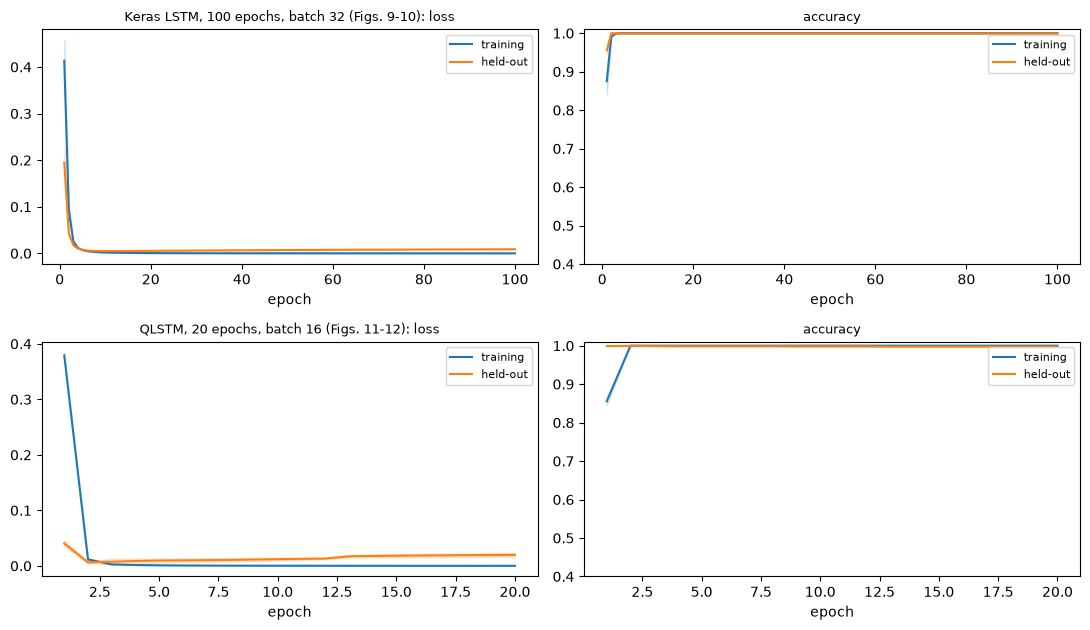

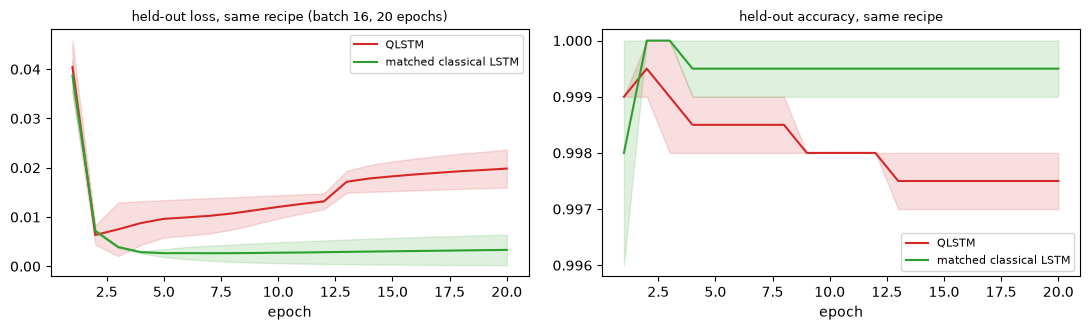

In [14]:
def band(ax, hs, key, label, color, ls="-"):
    A = np.array([h[key] for h in hs]); m, sd = A.mean(0), A.std(0); xs = np.arange(1, A.shape[1] + 1)
    ax.plot(xs, m, label=label, color=color, ls=ls); ax.fill_between(xs, m - sd, m + sd, color=color, alpha=.15)

kk = lambda h: {"loss": h["loss"], "acc": h["accuracy"], "val_loss": h["val_loss"], "val_acc": h["val_accuracy"]}
HK = [kk(h) for h in HIST["Keras LSTM (paper)"]]
fig, ax = plt.subplots(2, 2, figsize=(11, 6.4))
for r_, (hs, ttl) in enumerate(((HK, f"Keras LSTM, {KERAS_EPOCHS} epochs, batch {KERAS_BATCH} (Figs. 9-10)"), (HIST["QLSTM (6 qubits)"], f"QLSTM, {Q_EPOCHS} epochs, batch {Q_BATCH} (Figs. 11-12)"))):
    band(ax[r_, 0], hs, "loss", "training", "tab:blue"); band(ax[r_, 0], hs, "val_loss", "held-out", "tab:orange"); ax[r_, 0].set_title(ttl + ": loss", fontsize=9)
    band(ax[r_, 1], hs, "acc", "training", "tab:blue"); band(ax[r_, 1], hs, "val_acc", "held-out", "tab:orange"); ax[r_, 1].set_title("accuracy", fontsize=9); ax[r_, 1].set_ylim(0.4, 1.01)
    for a in ax[r_]: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
band(ax[0], HIST["QLSTM (6 qubits)"], "val_loss", "QLSTM", "tab:red"); band(ax[0], HIST["matched classical LSTM"], "val_loss", "matched classical LSTM", "tab:green")
band(ax[1], HIST["QLSTM (6 qubits)"], "val_acc", "QLSTM", "tab:red"); band(ax[1], HIST["matched classical LSTM"], "val_acc", "matched classical LSTM", "tab:green")
ax[0].set_title("held-out loss, same recipe (batch 16, 20 epochs)", fontsize=9); ax[1].set_title("held-out accuracy, same recipe", fontsize=9)
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

*Tables I and II analogue.* Recall, precision, accuracy and F1 (DDoS = positive class) at the last epoch, mean and standard deviation over seeds, for every model, and the confusion matrices of the first seed.

                   model       recall %    precision %     accuracy %           f1 % train+predict s  runs
      Keras LSTM (paper)  99.81 +- 0.00 100.00 +- 0.00  99.90 +- 0.00  99.90 +- 0.00             326     2
   Random Forest, window 100.00 +- 0.00 100.00 +- 0.00 100.00 +- 0.00 100.00 +- 0.00               3     2
Random Forest, last flow 100.00 +- 0.00  99.90 +- 0.10  99.95 +- 0.05  99.95 +- 0.05               2     2
       SVC (RBF), window 100.00 +- 0.00 100.00 +- 0.00 100.00 +- 0.00 100.00 +- 0.00               0     1
    SVC (RBF), last flow 100.00 +- 0.00  99.61 +- 0.00  99.80 +- 0.00  99.81 +- 0.00               0     1
        QLSTM (6 qubits)  99.71 +- 0.10  99.81 +- 0.19  99.75 +- 0.05  99.76 +- 0.05             298     2
  matched classical LSTM  99.90 +- 0.10 100.00 +- 0.00  99.95 +- 0.05  99.95 +- 0.05              23     2


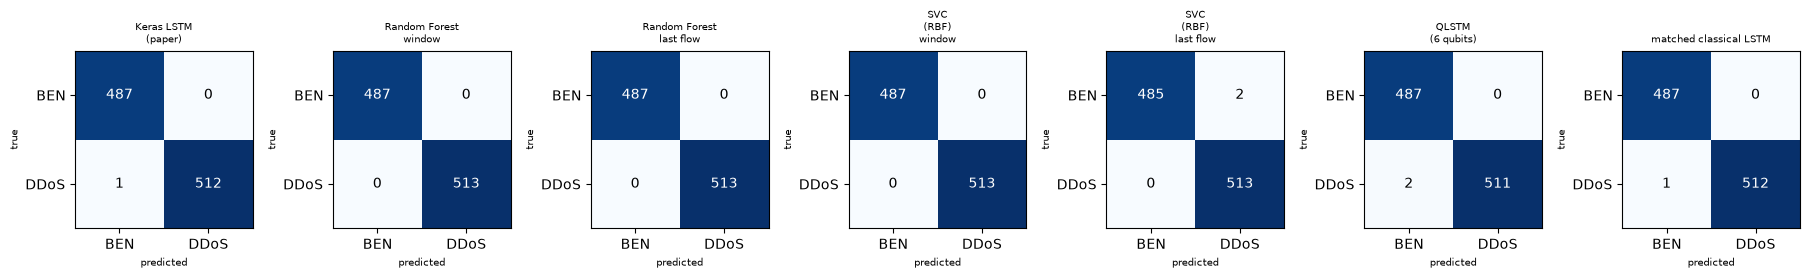

In [15]:
rows = []
for nm, rs in RESULTS.items():
    d = {"model": nm}
    for m_ in ("recall", "precision", "accuracy", "f1"):
        v = np.array([r[m_] for r in rs]) * 100; d[m_ + " %"] = f"{v.mean():.2f} +- {v.std():.2f}"
    d["train+predict s"] = f"{np.mean([r['seconds'] for r in rs]):.0f}"; d["runs"] = len(rs); rows.append(d)
TAB = pd.DataFrame(rows); print(TAB.to_string(index=False))

order = list(CM)
fig, ax = plt.subplots(1, len(order), figsize=(2.6 * len(order), 2.9))
for a, nm in zip(np.atleast_1d(ax), order):
    cm = CM[nm]; a.imshow(cm, cmap="Blues"); a.set_xticks([0, 1]); a.set_xticklabels(["BEN", "DDoS"]); a.set_yticks([0, 1]); a.set_yticklabels(["BEN", "DDoS"])
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha="center", va="center", color="w" if cm[i, j] > cm.max() / 2 else "k")
    a.set_title(nm.replace(", ", "\n").replace(" (", "\n("), fontsize=7); a.set_xlabel("predicted", fontsize=7); a.set_ylabel("true", fontsize=7)
plt.tight_layout(); plt.show()

## 8. Side by side with the paper, claim by claim

Verdict rule (from the project brief): a metric is **reproduced** when our value lies within 2 percentage points of the paper's (0.02 for F1), otherwise **exceeded** (ours higher) or **not reached** (ours lower) with the gap; **cannot be checked** when the claim cannot be tested with the information the paper gives. For the paper's Keras LSTM and the QLSTM we compare with Tables I and II; "ours" is the mean over seeds at the last epoch.

In [16]:
def mean_of(nm, m_): return 100 * float(np.mean([r[m_] for r in RESULTS[nm]]))
def verdict(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")
PAPER_T1 = {"recall": 90.06, "precision": 99.82, "accuracy": 90.24, "f1": 94.69}      # Table I, classical LSTM
PAPER_T2 = {"recall": 99.65, "precision": 99.43, "accuracy": 99.65, "f1": 99.69}      # Table II, QLSTM
rows = []
for m_ in ("recall", "precision", "accuracy", "f1"):
    o = mean_of("Keras LSTM (paper)", m_); rows.append(["Table I, classical LSTM: " + m_, f"{PAPER_T1[m_]:.2f}%", f"{o:.2f}%", verdict(o, PAPER_T1[m_])])
for m_ in ("recall", "precision", "accuracy", "f1"):
    o = mean_of("QLSTM (6 qubits)", m_); rows.append(["Table II, QLSTM: " + m_, f"{PAPER_T2[m_]:.2f}%", f"{o:.2f}%", verdict(o, PAPER_T2[m_])])

# text claims
hk = HIST["Keras LSTM (paper)"]; hq = HIST["QLSTM (6 qubits)"]
k_acc_last = 100 * float(np.mean([h["accuracy"][-1] for h in hk])); k_loss_last = float(np.mean([h["loss"][-1] for h in hk]))
rows.append(["Text: classical LSTM final training accuracy .9983", "99.83%", f"{k_acc_last:.2f}%", verdict(k_acc_last, 99.83)])
rows.append(["Text: classical LSTM final loss .0088", "0.0088", f"{k_loss_last:.4f}", "reproduced" if abs(k_loss_last - 0.0088) <= 0.005 else ("higher loss" if k_loss_last > 0.0088 else "lower loss")])
q_tr = 100 * float(np.mean([h["acc"][-1] for h in hq])); q_va = 100 * float(np.mean([h["val_acc"][-1] for h in hq]))
q_trl = float(np.mean([h["loss"][-1] for h in hq])); q_val = float(np.mean([h["val_loss"][-1] for h in hq]))
rows.append(["Text: QLSTM training accuracy 0.995", "99.5%", f"{q_tr:.2f}%", verdict(q_tr, 99.5)])
rows.append(["Text: QLSTM validation accuracy 1.0", "100%", f"{q_va:.2f}%", verdict(q_va, 100.0)])
rows.append(["Text: QLSTM training loss about 0.03", "0.03", f"{q_trl:.4f}", "reproduced" if abs(q_trl - 0.03) <= 0.005 else ("higher loss" if q_trl > 0.03 else "lower loss")])
rows.append(["Text: QLSTM validation loss 0.0195", "0.0195", f"{q_val:.4f}", "reproduced" if abs(q_val - 0.0195) <= 0.005 else ("higher loss" if q_val > 0.0195 else "lower loss")])
fast_q = int(np.mean([next((i + 1 for i, a in enumerate(h["val_acc"]) if a >= 0.99), Q_EPOCHS + 1) for h in hq]))
fast_k = int(np.mean([next((i + 1 for i, a in enumerate(h["val_accuracy"]) if a >= 0.99), KERAS_EPOCHS + 1) for h in hk]))
rows.append(["Abstract: both models reach accuracy >= 0.99 within a few epochs", "a few epochs", f"held-out acc >= .99 at epoch {fast_k} (Keras), {fast_q} (QLSTM)",
             "reproduced" if max(fast_q, fast_k) <= 10 else "not reached within 10 epochs"])

# ranking claims
for m_ in ("recall", "precision", "accuracy", "f1"):
    pass
wins = {m_: (mean_of("QLSTM (6 qubits)", m_) > mean_of("Keras LSTM (paper)", m_), mean_of("QLSTM (6 qubits)", m_) > mean_of("matched classical LSTM", m_)) for m_ in ("recall", "precision", "accuracy", "f1")}
rows.append(["Claim: QLSTM beats the classical LSTM on all four metrics (vs Keras LSTM)", "4 of 4", f"{sum(w[0] for w in wins.values())} of 4", "reproduced" if all(w[0] for w in wins.values()) else "not reached"])
rows.append(["Claim: QLSTM beats the classical LSTM on all four metrics (vs matched LSTM, same recipe)", "4 of 4", f"{sum(w[1] for w in wins.values())} of 4", "reproduced" if all(w[1] for w in wins.values()) else "not reached"])
t_q = np.mean([r["seconds"] for r in RESULTS["QLSTM (6 qubits)"]]); t_l = np.mean([r["seconds"] for r in RESULTS["matched classical LSTM"]])
rows.append(["Claim: QLSTM takes more time to train (simulation)", "slower", f"x{t_q / t_l:.1f} vs matched LSTM ({t_q:.0f}s vs {t_l:.0f}s)", "reproduced" if t_q > t_l else "not reached"])
# internal consistency of the paper's tables
f1_from_pr = lambda p, r: 2 * p * r / (p + r)
rows.append(["Check: Table I F1 follows from its precision and recall", f"{PAPER_T1['f1']:.2f}%", f"{f1_from_pr(PAPER_T1['precision'], PAPER_T1['recall']):.2f}%", "consistent"])
rows.append(["Check: Table II F1 follows from its precision and recall", f"{PAPER_T2['f1']:.2f}%", f"{f1_from_pr(PAPER_T2['precision'], PAPER_T2['recall']):.2f}%", "inconsistent (F1 is the harmonic mean of the two)"])
CMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
print(CMP.to_string(index=False))

                                                                                   claim        paper                                     this notebook                                           verdict
                                                         Table I, classical LSTM: recall       90.06%                                            99.81%                                   exceeded (+9.7)
                                                      Table I, classical LSTM: precision       99.82%                                           100.00%                                        reproduced
                                                       Table I, classical LSTM: accuracy       90.24%                                            99.90%                                   exceeded (+9.7)
                                                             Table I, classical LSTM: f1       94.69%                                            99.90%                                   exceed

## 9. Reading the paper critically

The headline of the paper is that the QLSTM beats the classical LSTM on recall, accuracy, precision and F1. What the paper itself shows, and what this notebook measured, supports a more careful reading:

1. **The tables contradict the text.** Section IV.A says the classical LSTM reaches accuracy .9983 with loss .0088 and "nearly 99% through 20 epochs", but Table I reports accuracy 90.24% and recall 90.06%. Table II's F1 (99.69%) is higher than the harmonic mean of its own precision and recall (99.54%), and its accuracy equals its recall to the last digit. One of these numbers is a typo or comes from a different run; the check rows above make this visible.
2. **Different recipes.** The classical model is trained for 100 epochs at batch size 1024 (about 100 x 176 updates on the full data), the quantum model for 20 epochs at batch size 16 (about 20 x 11,000 updates). With 64 times more parameter updates the QLSTM has an advantage that has nothing to do with qubits. The matched classical LSTM in this notebook removes that confound.
3. **The problem is easy.** In this capture the DDoS flows are an HTTP flood that differs strongly from normal traffic, and flows of the same kind arrive in long runs. A Random Forest on the *last flow only* is already near-perfect, so a high accuracy says little about the quantum component.
4. **What is predicted?** With the label of the flow after the window, a network that only learns "traffic looked like an attack a moment ago" scores very well. A harder, more honest test would hold out whole attack episodes or other days.
5. **No uncertainty.** The paper gives one run without seeds, the split is not described, the validation accuracy of exactly 1.0 suggests the validation set is easy or overlaps with the training windows (windows with stride 1 overlap in 9 of 10 flows, so a random split leaks).
6. **Simulation only.** All quantum results are noiseless state-vector simulations; noise, shot noise and hardware limits are not addressed.
7. **What we measured (executed FAST_MODE run).** Every model, quantum or classical, ends between about 99.7% and 100% accuracy on the held-out blocks; the QLSTM is slightly *below* the Keras LSTM and the matched classical LSTM, and about 8 times slower. Table I's 90% for the classical LSTM is not reproduced by any classical model here, Table II's values are matched, but only because the task leaves no room below them. Neither the paper's ranking (QLSTM better than LSTM) nor its opposite can be concluded from differences of a few flows out of 1,000 with two seeds.

## 10. Exercises

1. **Depth and qubits.** Change `Q_DEPTH` (1, 2, 3) and `N_QUBITS` (3, 4, 6, 8) and plot held-out F1 against the number of circuit parameters. Does anything beat the matched classical LSTM?
2. **Remove the quantum part.** Replace `expect_twin` in `QLSTM` by a small classical layer with the same input and output size (6 numbers in, 6 out) and compare parameter counts and accuracy. Is the circuit doing anything a tiny classical layer cannot?
3. **A harder split.** Hold out one contiguous stretch of the file (for example the last 30% of the attack period) instead of random blocks and repeat the comparison.
4. **Label of the last flow.** Change the window label from the flow after the window to the last flow inside it and compare all models. Which one is the easier task?
5. **Shots.** Replace the exact expectation values by estimates from 100 or 1000 measurement shots (add Gaussian noise of variance (1 - <Z>^2) / shots to `q`) and see how the held-out accuracy degrades.